<h1>Train — EfficientNet-B0</h1>

Trains and evaluates EfficientNet-B0 using the tuned hyperparameters from `ARCH_HYPERPARAMS["efficientnet_b0"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["efficientnet_b0"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"EfficientNet-B0: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

EfficientNet-B0: micro batch = 16, accumulation steps = 1 (effective batch size ≈ 16, tuned value = 16)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with EfficientNet-B0)
# ---------------------------------------------------------
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# EfficientNet's classifier is nn.Sequential(Dropout, Linear) — swap out
# just the Linear layer for our (optionally deeper) classifier head, same
# as the fc/classifier swaps used for the other architectures.
in_f = model.classifier[1].in_features
model.classifier[1] = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[EfficientNet-B0] Epoch   1/100 | LR: 1.72e-04 | train loss 0.8890 acc 0.652 | val loss 0.6767 acc 0.716 *


[EfficientNet-B0] Epoch   2/100 | LR: 1.72e-04 | train loss 0.6297 acc 0.765 | val loss 0.5904 acc 0.729 *


[EfficientNet-B0] Epoch   3/100 | LR: 1.72e-04 | train loss 0.5358 acc 0.795 | val loss 0.5341 acc 0.760 *


[EfficientNet-B0] Epoch   4/100 | LR: 1.72e-04 | train loss 0.3767 acc 0.866 | val loss 0.6094 acc 0.782


[EfficientNet-B0] Epoch   5/100 | LR: 1.72e-04 | train loss 0.2897 acc 0.890 | val loss 0.5847 acc 0.803


...

[EfficientNet-B0] Epoch   9/100 | LR: 1.72e-04 | train loss 0.1179 acc 0.965 | val loss 0.7086 acc 0.799


[EfficientNet-B0] Epoch  10/100 | LR: 1.72e-04 | train loss 0.1936 acc 0.938 | val loss 0.6932 acc 0.821


[EfficientNet-B0] Epoch  11/100 | LR: 1.72e-04 | train loss 0.1398 acc 0.946 | val loss 0.9322 acc 0.786


[EfficientNet-B0] Epoch  12/100 | LR: 1.72e-04 | train loss 0.1311 acc 0.956 | val loss 0.6942 acc 0.808


[EfficientNet-B0] Epoch  13/100 | LR: 1.72e-04 | train loss 0.0790 acc 0.968 | val loss 0.9406 acc 0.795

[EfficientNet-B0] No val loss improvement for 10 epochs — stopping early at epoch 13.

[EfficientNet-B0] Restored best checkpoint (val loss = 0.5341)


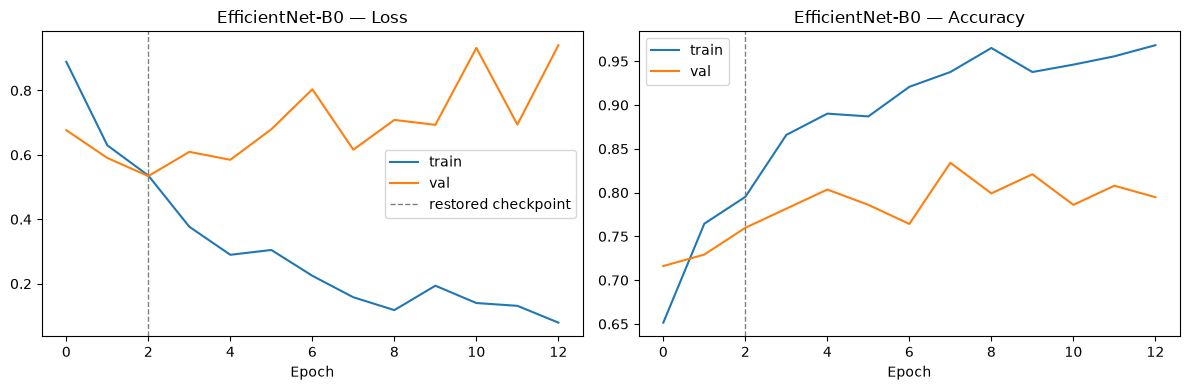

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "EfficientNet-B0", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "EfficientNet-B0")

## Evaluate on the test set

[EfficientNet-B0] Test accuracy: 0.808


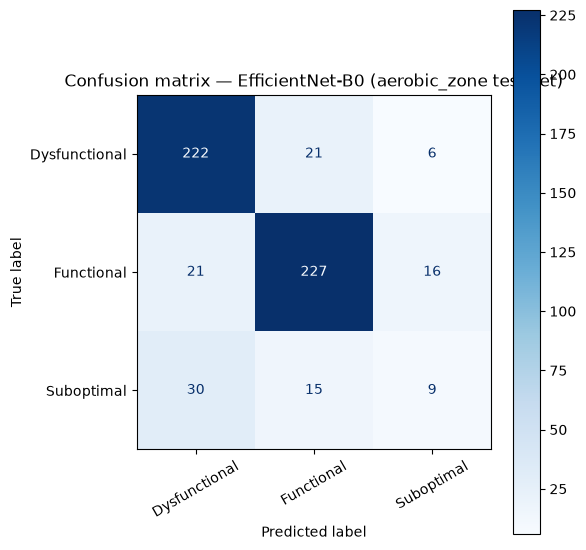

               precision    recall  f1-score   support

Dysfunctional      0.813     0.892     0.851       249
   Functional      0.863     0.860     0.861       264
   Suboptimal      0.290     0.167     0.212        54

     accuracy                          0.808       567
    macro avg      0.656     0.639     0.641       567
 weighted avg      0.787     0.808     0.795       567



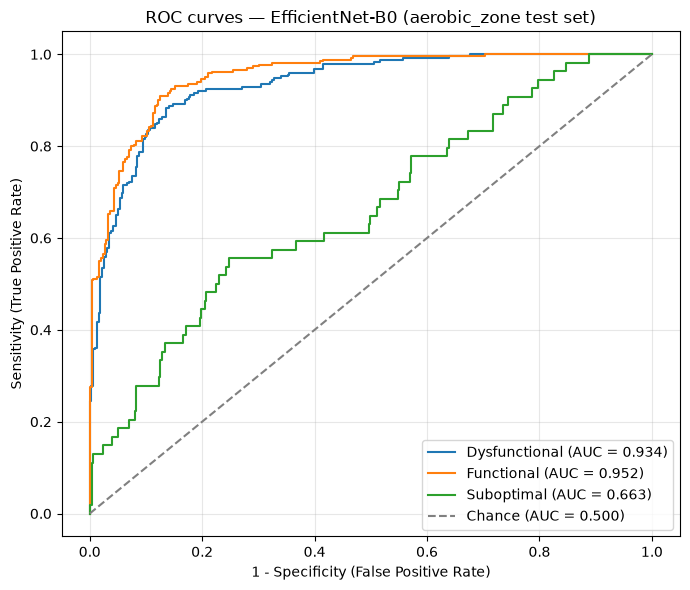

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.934
  Functional     : 0.952
  Suboptimal     : 0.663

Mean AUC (over 3/3 classes with test examples): 0.849


(np.float64(0.8077601410934744),
 {'Dysfunctional': 0.9337601980248037,
  'Functional': 0.9517451745174518,
  'Suboptimal': 0.6628402281423724})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "EfficientNet-B0", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("EfficientNet-B0", "efficientnet_b0")

Saved results to ../results/aerobic_zone_noaug/results_aerobic_zone_efficientnet_b0_chronological.pkl


Saved model weights to ../models/pad/aerobic_zone_efficientnet_b0_cnn.pt
